# IS 362 – Week 8 Assignment
## Exploring the Auto MPG Dataset

In this assignment, I will use the Auto MPG dataset from the UCI Machine Learning Repository to explore different vehicle characteristics. I will clean up the data, look at how different variables are distributed, and create graphs to better understand the relationships between them.

In [7]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

columns = [
    "mpg", "cylinders", "displacement", "horsepower",
    "weight", "acceleration", "model_year", "origin", "car_name"
]

df = pd.read_csv(
    "auto-mpg.data",
    sep=r"\s+",
    names=columns,
    na_values="?",
    quotechar='"'
)

df.head()


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


In [8]:

# Review the dataset
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

# Convert horsepower to numeric
df["horsepower"] = pd.to_numeric(df["horsepower"], errors="coerce")

# Replace origin numbers with region names
df["origin"] = df["origin"].replace({
    1: "USA",
    2: "Asia",
    3: "Europe"
})

# Display cleaned data
df.head()


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    str    
dtypes: float64(5), int64(3), str(1)
memory usage: 28.1 KB

Missing Values:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,USA,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,USA,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,USA,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,USA,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,USA,ford torino


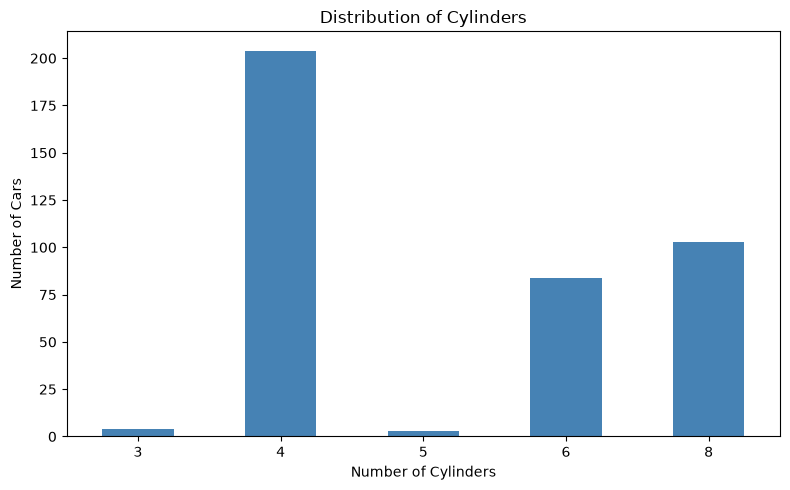

In [9]:

# Bar chart showing the distribution of cylinders

plt.figure(figsize=(8, 5))

df["cylinders"].value_counts().sort_index().plot(
    kind="bar",
    color="steelblue"
)

plt.title("Distribution of Cylinders")
plt.xlabel("Number of Cylinders")
plt.ylabel("Number of Cars")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Distribution of Cylinders

The bar chart shows that four-cylinder cars are the most common in the dataset, followed by eight-cylinder and six-cylinder cars. Cars with three or five cylinders are much less common. This gives a better idea of which engine types were represented the most in the dataset.

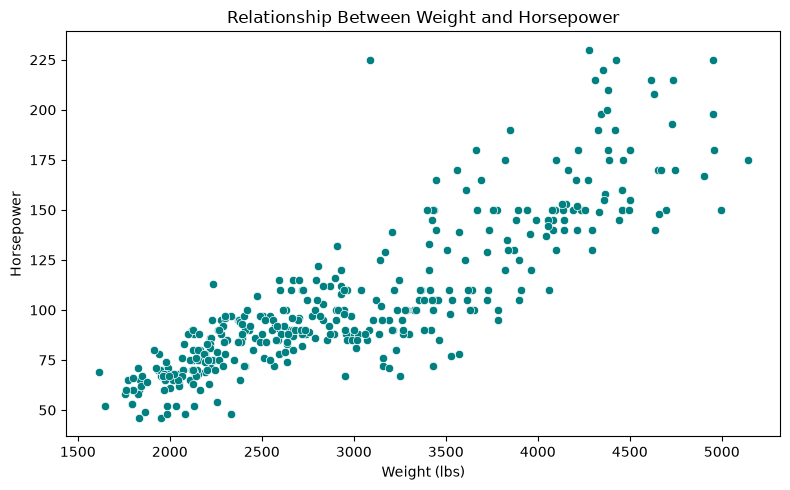

In [10]:

# Scatterplot showing the relationship between horsepower and weight

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="weight",
    y="horsepower",
    color="teal"
)

plt.title("Relationship Between Weight and Horsepower")
plt.xlabel("Weight (lbs)")
plt.ylabel("Horsepower")
plt.tight_layout()
plt.show()


### Relationship Between Horsepower and Weight

The scatterplot shows that heavier cars generally have more horsepower. As the weight of a car increases, its horsepower tends to increase as well. There are some exceptions, but overall the graph shows a pretty clear positive relationship between the two variables.

### Research Question: Does Fuel Efficiency Differ by Region?

For my final analysis, I wanted to see whether cars from different regions had different average miles per gallon (MPG). I compared cars from the USA, Asia, and Europe to see which region had the highest average fuel efficiency.

Average MPG by Region:
origin
Asia      27.89
Europe    30.45
USA       20.08
Name: mpg, dtype: float64


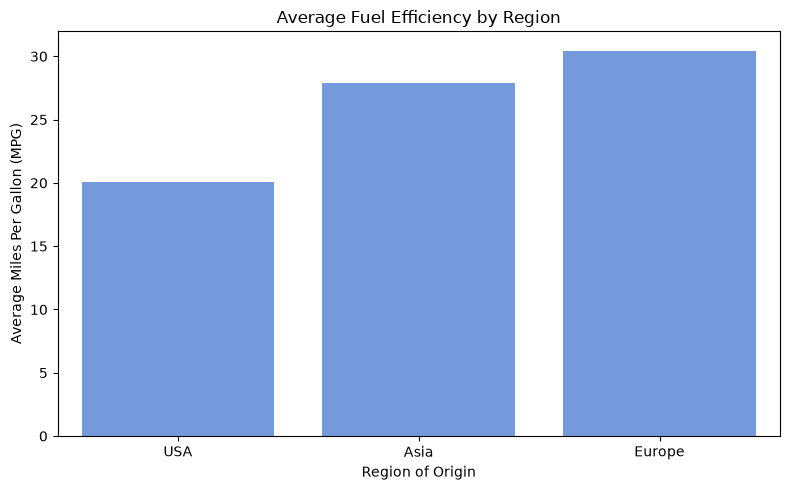

In [11]:

# Research Question: Does average MPG differ by region?

average_mpg = df.groupby("origin")["mpg"].mean()

print("Average MPG by Region:")
print(average_mpg.round(2))

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="origin",
    y="mpg",
    order=["USA", "Asia", "Europe"],
    color="cornflowerblue",
    errorbar=None
)

plt.title("Average Fuel Efficiency by Region")
plt.xlabel("Region of Origin")
plt.ylabel("Average Miles Per Gallon (MPG)")
plt.tight_layout()
plt.show()


### Findings and Conclusion

Based on the graph, cars from Asia have the highest average MPG, followed by cars from Europe. Cars from the USA have the lowest average MPG. This suggests that cars from Asia and Europe were generally more fuel-efficient than American cars in this dataset.

However, other factors like vehicle weight, engine size, and model year could also affect fuel efficiency. Overall, I found it interesting to see how much average MPG varied between the regions.